# Logistic Regression — Hyperparameter Tuning

Loads the shared train/val/test splits saved by `data_eda.ipynb`, vectorizes with TF-IDF (update the
config below if `bow_vs_tfidf.ipynb` found a better one than the default), then grid-searches
Logistic Regression's key hyperparameters. Every candidate combination is logged to MLflow, and the best model
gets registered.

Run `data_eda.ipynb` first — this notebook depends on the CSVs it saves.

In [1]:
# ── libraries ──
import os
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression, SGDClassifier

import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ── config + load the shared splits ──
MODEL_NAME = "LogisticRegression"
SEED = 42

DATA_DIR = "../data/processed"
RESULTS_DIR = "results"
MODELS_DIR = "saved_models"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

MLFLOW_EXPERIMENT = "IndianFinSentiment_ClassicalML"
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment(MLFLOW_EXPERIMENT)

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
print(f"Train: {len(train_df)}  |  Val: {len(val_df)}  |  Test: {len(test_df)}")

Train: 7094  |  Val: 946  |  Test: 1419


## Vectorize with TF-IDF

**Update these two values** if `bow_vs_tfidf.ipynb` found a better config than this default.

In [3]:
TFIDF_MAX_FEATURES = 15_000
TFIDF_NGRAM_RANGE = (1, 2)

vectorizer = TfidfVectorizer(max_features=TFIDF_MAX_FEATURES, ngram_range=TFIDF_NGRAM_RANGE, min_df=2)
X_train = vectorizer.fit_transform(train_df["text"])
X_val = vectorizer.transform(val_df["text"])
X_test = vectorizer.transform(test_df["text"])

y_train, y_val, y_test = train_df["label_id"], val_df["label_id"], test_df["label_id"]
print(f"TF-IDF matrix shape: {X_train.shape}")

TF-IDF matrix shape: (7094, 11720)


In [4]:
def evaluate(y_true, y_pred):
    per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2])
    return {
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "f1_weighted": round(f1_score(y_true, y_pred, average="weighted"), 4),
        "f1_positive": round(per_class[0], 4),
        "f1_neutral": round(per_class[1], 4),
        "f1_negative": round(per_class[2], 4),
    }


def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1)[:, None]
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm_pct, annot=True, fmt=".1%", cmap="Blues",
                xticklabels=["positive", "neutral", "negative"],
                yticklabels=["positive", "neutral", "negative"], ax=ax)
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    path = f"{RESULTS_DIR}/cm_{name.lower().replace(' ', '_')}.png"
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()
    return path

## Broader hyperparameter search

The old version of this notebook only searched `C` (4 values, `solver="lbfgs"` fixed) — 4
candidates x 3-fold CV = 12 fits, done in ~6 seconds. That's not really a hyperparameter search,
and with `n_jobs=-1` and no verbosity it also printed nothing while running, which made it look
like nothing was happening.

This version searches three real axes with `solver="saga"` (the only solver that supports L1,
L2, *and* elasticnet penalties, needed to cover all three):
- `C` — inverse regularization strength, 10 values from 0.001 to 30
- `l1_ratio` — 0.0 = pure L2, 1.0 = pure L1, anything between = elasticnet (sklearn's current
  API folds the old `penalty` parameter into this single continuous knob)
- `class_weight` — `None` vs `"balanced"`, since the data is mildly imbalanced (36% neutral /
  35% positive / 28.5% negative)

That's 10 x 5 x 2 = 100 combinations, searched with `RandomizedSearchCV` (30 sampled
combinations, not all 100 — full grid at 5-fold CV would be 500 fits) and `verbose=2`, so you'll
see every fold's fit print as it happens.

In [5]:
model = LogisticRegression(solver="saga", max_iter=3000, random_state=SEED)

param_distributions = {
    "C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30],
    "l1_ratio": [0.0, 0.15, 0.5, 0.85, 1.0],
    "class_weight": [None, "balanced"],
}

start = time.time()
random_search = RandomizedSearchCV(
    model, param_distributions, n_iter=30, cv=5, scoring="f1_weighted",
    n_jobs=-1, random_state=SEED, verbose=2,
)
random_search.fit(X_train, y_train)
search_time = time.time() - start

n_combos = len(random_search.cv_results_["params"])
print(f"\nRandom search done in {search_time:.1f}s — tried {n_combos} combinations x 5-fold CV = {n_combos * 5} fits")
print(f"Best params: {random_search.best_params_}")
print(f"Best CV F1 (weighted): {random_search.best_score_:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits



Random search done in 499.4s — tried 30 combinations x 5-fold CV = 150 fits
Best params: {'l1_ratio': 0.85, 'class_weight': 'balanced', 'C': 10}
Best CV F1 (weighted): 0.8191


## Log every candidate combination to MLflow

In [6]:
for params, mean_score, std_score in zip(
    random_search.cv_results_["params"],
    random_search.cv_results_["mean_test_score"],
    random_search.cv_results_["std_test_score"],
):
    run_name = f"{MODEL_NAME}_" + "_".join(f"{k}={v}" for k, v in params.items())
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params)
        mlflow.log_metric("cv_f1_weighted_mean", round(float(mean_score), 4))
        mlflow.log_metric("cv_f1_weighted_std", round(float(std_score), 4))

print(f"Logged {len(random_search.cv_results_['params'])} candidate runs to MLflow.")

Logged 30 candidate runs to MLflow.


## Overfitting check: train vs val vs test (CV-best model)

Before doing anything else with the winning hyperparameters, check whether it's actually
overfitting — a big train/val gap is the tell.

In [7]:
cv_best_model = random_search.best_estimator_
train_metrics_cv = evaluate(y_train, cv_best_model.predict(X_train))
val_metrics_cv = evaluate(y_val, cv_best_model.predict(X_val))
test_metrics_cv = evaluate(y_test, cv_best_model.predict(X_test))

print(f"{'Split':<8} {'Accuracy':>10} {'F1 (weighted)':>14}")
for name, m in [("Train", train_metrics_cv), ("Val", val_metrics_cv), ("Test", test_metrics_cv)]:
    print(f"{name:<8} {m['accuracy']:>10.4f} {m['f1_weighted']:>14.4f}")

gap = train_metrics_cv["f1_weighted"] - val_metrics_cv["f1_weighted"]
print(f"\nTrain-Val F1 gap: {gap:.4f} (large positive gap = overfitting)")

Split      Accuracy  F1 (weighted)
Train        0.9989         0.9989
Val          0.8171         0.8172
Test         0.8132         0.8133

Train-Val F1 gap: 0.1817 (large positive gap = overfitting)


## Epoch-based training (SGD) with early stopping

`LogisticRegression(solver="saga", ...)` converges via internal iterative optimization, but
doesn't expose a per-epoch train/val curve — it's a black box that returns a finished model.
`SGDClassifier(loss="log_loss", ...)` is mathematically the same model (logistic regression)
but trained via stochastic gradient descent through `partial_fit()`, which *does* let us step
through training one epoch at a time, watch train/val F1 move, and stop early the moment val F1
stops improving — the same pattern used for the deep learning notebooks in this project.

Uses the winning `l1_ratio`/`class_weight` from the search above, with `alpha` (SGD's
regularization strength) derived from the winning `C` via `alpha ≈ 1/(C · n_samples)` — the
standard conversion between the two parameterizations.

 Epoch | train_acc  train_f1 |   val_acc    val_f1 |  test_acc   test_f1
----------------------------------------------------------------------------
     1 |    0.9755    0.9755 |    0.7928    0.7928 |    0.7984    0.7982
     2 |    0.9949    0.9949 |    0.8150    0.8149 |    0.8020    0.8019
     3 |    0.9972    0.9972 |    0.8182    0.8182 |    0.8027    0.8027
     4 |    0.9986    0.9986 |    0.8118    0.8119 |    0.8104    0.8106
     5 |    0.9986    0.9986 |    0.8129    0.8130 |    0.8083    0.8084
     6 |    0.9983    0.9983 |    0.8150    0.8151 |    0.8076    0.8077
     7 |    0.9987    0.9987 |    0.8140    0.8140 |    0.8125    0.8127
     8 |    0.9987    0.9987 |    0.8129    0.8130 |    0.8090    0.8091
     9 |    0.9987    0.9987 |    0.8140    0.8141 |    0.8076    0.8076
    10 |    0.9987    0.9987 |    0.8182    0.8183 |    0.8097    0.8098
    11 |    0.9986    0.9986 |    0.8171    0.8172 |    0.8090    0.8091
    12 |    0.9989    0.9989 |    0.8161    0.8

    13 |    0.9987    0.9987 |    0.8161    0.8162 |    0.8069    0.8070
    14 |    0.9989    0.9989 |    0.8171    0.8172 |    0.8090    0.8091


    15 |    0.9989    0.9989 |    0.8203    0.8204 |    0.8104    0.8105
    16 |    0.9989    0.9989 |    0.8192    0.8194 |    0.8090    0.8091
    17 |    0.9987    0.9987 |    0.8129    0.8130 |    0.8069    0.8070
    18 |    0.9989    0.9989 |    0.8192    0.8194 |    0.8097    0.8098
    19 |    0.9987    0.9987 |    0.8171    0.8172 |    0.8076    0.8077
    20 |    0.9987    0.9987 |    0.8171    0.8172 |    0.8090    0.8091
    21 |    0.9987    0.9987 |    0.8171    0.8172 |    0.8090    0.8091
    22 |    0.9989    0.9989 |    0.8182    0.8183 |    0.8104    0.8106
    23 |    0.9989    0.9989 |    0.8182    0.8183 |    0.8090    0.8091
    24 |    0.9989    0.9989 |    0.8171    0.8172 |    0.8090    0.8091
    25 |    0.9989    0.9989 |    0.8171    0.8172 |    0.8090    0.8091

Early stopping at epoch 25 (best was epoch 15, val_f1=0.8204)


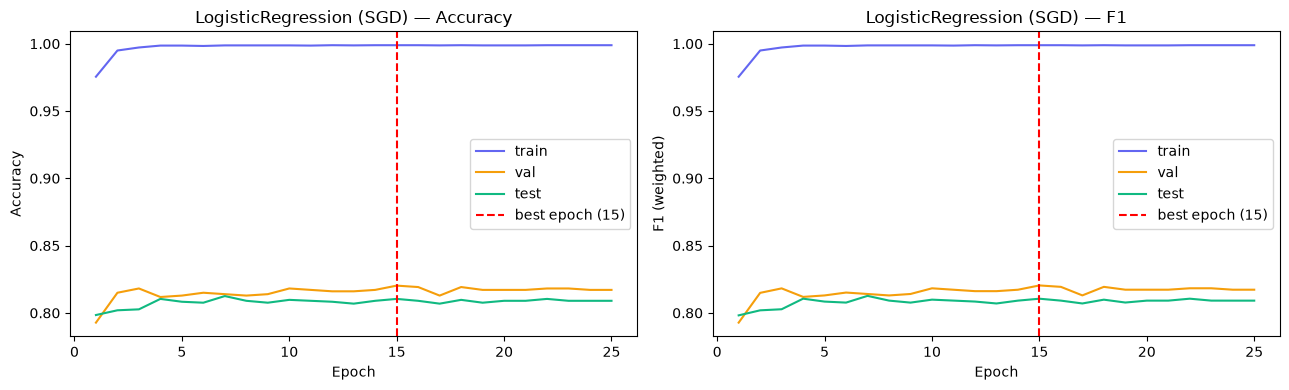

In [8]:
best_params = random_search.best_params_
sgd_alpha = 1.0 / (best_params["C"] * X_train.shape[0])

MAX_EPOCHS = 100
PATIENCE = 10

classes = np.array(sorted(y_train.unique()))

# SGDClassifier.partial_fit() can't accept class_weight="balanced" directly — it needs the full
# label distribution upfront to compute balanced weights, which isn't available incrementally.
# Precompute the equivalent per-class weight dict instead (same weights "balanced" would use).
if best_params["class_weight"] == "balanced":
    from sklearn.utils.class_weight import compute_class_weight
    weights = compute_class_weight("balanced", classes=classes, y=y_train)
    sgd_class_weight = dict(zip(classes.tolist(), weights.tolist()))
else:
    sgd_class_weight = None

sgd_model = SGDClassifier(
    loss="log_loss", penalty="elasticnet", l1_ratio=best_params["l1_ratio"], alpha=sgd_alpha,
    class_weight=sgd_class_weight, random_state=SEED,
)

y_train_arr, y_val_arr, y_test_arr = y_train.values, y_val.values, y_test.values
n_train = X_train.shape[0]
rng = np.random.RandomState(SEED)

best_val_f1, best_epoch, epochs_no_improve = -1.0, 0, 0
best_coef, best_intercept = None, None
history = []

print(f"{'Epoch':>6} | {'train_acc':>9} {'train_f1':>9} | {'val_acc':>9} {'val_f1':>9} | {'test_acc':>9} {'test_f1':>9}")
print("-" * 76)
for epoch in range(1, MAX_EPOCHS + 1):
    perm = rng.permutation(n_train)
    sgd_model.partial_fit(X_train[perm], y_train_arr[perm], classes=classes)

    train_pred = sgd_model.predict(X_train)
    val_pred = sgd_model.predict(X_val)
    test_pred = sgd_model.predict(X_test)   # informational only — never used to pick the epoch

    train_acc = accuracy_score(y_train_arr, train_pred)
    train_f1 = f1_score(y_train_arr, train_pred, average="weighted")
    val_acc = accuracy_score(y_val_arr, val_pred)
    val_f1 = f1_score(y_val_arr, val_pred, average="weighted")
    test_acc = accuracy_score(y_test_arr, test_pred)
    test_f1 = f1_score(y_test_arr, test_pred, average="weighted")
    history.append({
        "epoch": epoch, "train_acc": train_acc, "train_f1": train_f1,
        "val_acc": val_acc, "val_f1": val_f1, "test_acc": test_acc, "test_f1": test_f1,
    })

    print(f"{epoch:>6} | {train_acc:>9.4f} {train_f1:>9.4f} | {val_acc:>9.4f} {val_f1:>9.4f} | "
          f"{test_acc:>9.4f} {test_f1:>9.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        best_coef, best_intercept = sgd_model.coef_.copy(), sgd_model.intercept_.copy()
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"\nEarly stopping at epoch {epoch} (best was epoch {best_epoch}, val_f1={best_val_f1:.4f})")
            break

sgd_model.coef_, sgd_model.intercept_ = best_coef, best_intercept
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["epoch"], history_df["train_acc"], label="train", color="#6366f1")
axes[0].plot(history_df["epoch"], history_df["val_acc"], label="val", color="#f59e0b")
axes[0].plot(history_df["epoch"], history_df["test_acc"], label="test", color="#10b981")
axes[0].axvline(best_epoch, color="red", linestyle="--", label=f"best epoch ({best_epoch})")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].set_title(f"{MODEL_NAME} (SGD) — Accuracy"); axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_f1"], label="train", color="#6366f1")
axes[1].plot(history_df["epoch"], history_df["val_f1"], label="val", color="#f59e0b")
axes[1].plot(history_df["epoch"], history_df["test_f1"], label="test", color="#10b981")
axes[1].axvline(best_epoch, color="red", linestyle="--", label=f"best epoch ({best_epoch})")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("F1 (weighted)"); axes[1].set_title(f"{MODEL_NAME} (SGD) — F1"); axes[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/training_curve_{MODEL_NAME.lower()}.png", dpi=120, bbox_inches="tight")
plt.show()

In [9]:
# ── the epoch-trained SGD model (best hyperparameters, trained for real epochs with early
# stopping) is the final model — always, not just when it happens to beat the one-shot CV fit.
# The CV-best number below is kept purely as an informational reference point. ──
sgd_test_metrics = evaluate(y_test, sgd_model.predict(X_test))

print(f"{'Model':<24} {'F1 (weighted)':>14} {'Accuracy':>10}")
print("-" * 50)
print(f"{'CV-best (saga, one-shot)':<24} {test_metrics_cv['f1_weighted']:>14.4f} {test_metrics_cv['accuracy']:>10.4f}")
print(f"{'SGD (epoch-trained)':<24} {sgd_test_metrics['f1_weighted']:>14.4f} {sgd_test_metrics['accuracy']:>10.4f}")

final_model, final_variant, final_test_metrics = sgd_model, "SGD_epoch", sgd_test_metrics
print(f"\nFinal model (epoch-trained, best hyperparameters): {MODEL_NAME} ({final_variant})")

Model                     F1 (weighted)   Accuracy
--------------------------------------------------
CV-best (saga, one-shot)         0.8133     0.8132
SGD (epoch-trained)              0.8105     0.8104

Final model (epoch-trained, best hyperparameters): LogisticRegression (SGD_epoch)


## Evaluate the best model on the held-out test set

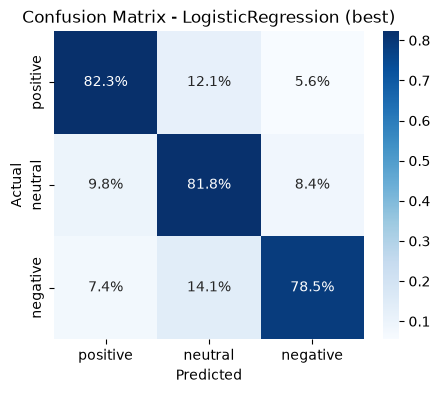

2026/07/19 17:20:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



LogisticRegression (SGD_epoch) — TEST RESULTS
              precision    recall  f1-score   support

    positive       0.84      0.82      0.83       503
     neutral       0.78      0.82      0.80       511
    negative       0.82      0.79      0.80       405

    accuracy                           0.81      1419
   macro avg       0.81      0.81      0.81      1419
weighted avg       0.81      0.81      0.81      1419



In [10]:
test_preds = final_model.predict(X_test)
test_metrics = evaluate(y_test, test_preds)

with mlflow.start_run(run_name=f"{MODEL_NAME}_BEST_{final_variant}"):
    if final_variant == "SGD_epoch":
        mlflow.log_params({
            "variant": final_variant, "C": best_params["C"], "l1_ratio": best_params["l1_ratio"],
            "class_weight": best_params["class_weight"], "alpha": sgd_alpha, "best_epoch": best_epoch,
        })
    else:
        mlflow.log_params({"variant": final_variant, **random_search.best_params_})
    mlflow.log_param("tfidf_max_features", TFIDF_MAX_FEATURES)
    mlflow.log_param("tfidf_ngram_range", str(TFIDF_NGRAM_RANGE))
    mlflow.log_metrics(test_metrics)
    mlflow.log_metric("cv_f1_weighted", round(random_search.best_score_, 4))
    mlflow.log_metric("search_time_seconds", round(search_time, 2))

    cm_path = plot_confusion_matrix(y_test, test_preds, f"{MODEL_NAME} (best)")
    mlflow.log_artifact(cm_path)
    mlflow.sklearn.log_model(final_model, "model")
    run_id = mlflow.active_run().info.run_id

print(f"\n{MODEL_NAME} ({final_variant}) — TEST RESULTS")
print(classification_report(y_test, test_preds, target_names=["positive", "neutral", "negative"]))

with open(f"{MODELS_DIR}/{MODEL_NAME.lower()}_best.pkl", "wb") as f:
    pickle.dump({"vectorizer": vectorizer, "model": final_model, "variant": final_variant}, f)

## Register the best model in the MLflow Model Registry

In [11]:
client = MlflowClient()
try:
    registered = mlflow.register_model(model_uri=f"runs:/{run_id}/model", name=f"{MODEL_NAME}_Classifier")
    print(f"Registered '{MODEL_NAME}_Classifier' version {registered.version}")
except Exception as e:
    print(f"Registration skipped/failed: {e}")

print(f"\nBest {MODEL_NAME} test F1 (weighted): {test_metrics['f1_weighted']:.4f}")

Registered model 'LogisticRegression_Classifier' already exists. Creating a new version of this model...
2026/07/19 17:21:03 WARNING mlflow.tracking._model_registry.fluent: Run with id ab68625fc86d4164826dc702cedb2390 has no artifacts at artifact path 'model', registering model based on models:/m-224839645b174a3ba70bd1e6ee92881a instead


Registered 'LogisticRegression_Classifier' version 5

Best LogisticRegression test F1 (weighted): 0.8105


Created version '5' of model 'LogisticRegression_Classifier'.
